In [1]:
import os
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from tqdm import tqdm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import gc
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
import sklearn as sk
import lightgbm
SEED = 42
os.chdir(r'D:\AFT\Feature_Engineer_Kaggle_2025')
import numpy as np
import pandas as pd
import os
import pandas as pd
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import math
import copy
import polars as pl
base_path = r'D:\AFT\Feature_Engineer_Kaggle_2025'  # 原始字符串
# 检查路径是否存在
if os.path.exists(base_path):
    for dirname, _, filenames in os.walk(base_path):
        for filename in filenames:
            print(os.path.join(dirname, filename))
else:
    print(f"路径不存在: {base_path}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

D:\AFT\Feature_Engineer_Kaggle_2025\.gitignore
D:\AFT\Feature_Engineer_Kaggle_2025\best_ae_transformer.pth
D:\AFT\Feature_Engineer_Kaggle_2025\best_model.pth
D:\AFT\Feature_Engineer_Kaggle_2025\best_model_weights.pth
D:\AFT\Feature_Engineer_Kaggle_2025\best_stable_model.pth
D:\AFT\Feature_Engineer_Kaggle_2025\best_stable_model_15.pth
D:\AFT\Feature_Engineer_Kaggle_2025\best_stable_model_20.pth
D:\AFT\Feature_Engineer_Kaggle_2025\best_stream_model.pth
D:\AFT\Feature_Engineer_Kaggle_2025\best_transformer_fast.pth
D:\AFT\Feature_Engineer_Kaggle_2025\Factor.py
D:\AFT\Feature_Engineer_Kaggle_2025\lgbm_ts_model.txt
D:\AFT\Feature_Engineer_Kaggle_2025\lgb_model_time_series.txt
D:\AFT\Feature_Engineer_Kaggle_2025\lightgbm_optimized_model.bin
D:\AFT\Feature_Engineer_Kaggle_2025\mae_distribution.png
D:\AFT\Feature_Engineer_Kaggle_2025\mae_results_predictions_20251208_100041.csv
D:\AFT\Feature_Engineer_Kaggle_2025\merged_features_new.parquet
D:\AFT\Feature_Engineer_Kaggle_2025\multilinear_and_tre

全局标准化，历史标准化，不同sequence

In [2]:
import polars as pl
import numpy as np
import gc

path = r"D:\AFT\Feature_Engineer_Kaggle_2025\selected_features_full_sample.parquet"
# ===== 1. 全量读取到内存（一次性） =====
print("Loading full parquet ...")
df = pl.read_parquet(path)
cols = df.columns
factor_cols = cols[3:-1]
target_col = "target"
df = df.sort(['date_id', 'seconds_in_bucket'])
# ===== 2. 按时间切分训练/验证 =====
n_total = df.height
n_train = int(n_total *5/6)
train_df = df.slice(0, n_train)
val_df = df.slice(n_train, n_total - n_train)
print(train_df.shape, val_df.shape)

# ===== 3. groupby(stock_id) → ffill =====
train_df = train_df.sort(["stock_id", "date_id", "seconds_in_bucket"])
train_df = train_df.with_columns([
    pl.col(c).forward_fill().over("stock_id") for c in train_df.columns
])
val_df = val_df.sort(["stock_id", "date_id", "seconds_in_bucket"])
val_df = val_df.with_columns([
    pl.col(c).forward_fill().over("stock_id") for c in val_df.columns
])

# ===== 4. 计算训练集的均值和标准差 =====
mean_dict = train_df.select([pl.col(c).mean().alias(c) for c in factor_cols]).row(0, named=True)
std_dict = train_df.select([pl.col(c).std().alias(c) for c in factor_cols]).row(0, named=True)
for c in factor_cols:
    if std_dict[c] is None or std_dict[c] == 0:
        std_dict[c] = 1e-6

# ===== 5. 标准化 + 缺失填 0 =====
def normalize(df):
    exprs = []
    for c in factor_cols:
        exprs.append(((pl.col(c) - mean_dict[c]) / std_dict[c]).fill_null(0).alias(c))
    return df.with_columns(exprs)

train_df = normalize(train_df)
val_df = normalize(val_df)
# ===== 6. 保存处理好的 parquet =====
train_path = r"D:\AFT\preprocess_train.parquet"
val_path = r"D:\AFT\preprocess_val.parquet"
train_df.write_parquet(train_path)
val_df.write_parquet(val_path)
print("Saved:", train_path, val_path)
#del df, train_df, val_df
gc.collect()
del train_df, val_df


Loading full parquet ...
(4364983, 104) (872997, 104)
Saved: D:\AFT\preprocess_train.parquet D:\AFT\preprocess_val.parquet


In [2]:
import polars as pl
import torch
from torch import nn
from torch.utils.data import IterableDataset, DataLoader
import numpy as np
from tqdm import tqdm
import warnings
import gc
import os
warnings.filterwarnings("ignore")
# ===========================================================
# 1. 添加调试和数值稳定性检查
# ===========================================================
# 检查CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)
print(f"CUDA device: {torch.cuda.get_device_name(0)}")
# 设置随机种子
torch.manual_seed(42)
torch.cuda.manual_seed(42)
np.random.seed(42)
train_path = r"D:\AFT\preprocess_train.parquet"
val_path   = r"D:\AFT\preprocess_val.parquet"
seq_len = 15
batch_size = 2048  # 先减小批次，方便调试
num_workers = 0
# ===========================================================
# 2. 数据加载与检查
# ===========================================================
print("Loading metadata and checking data quality...")
def check_data_quality(path):
    """检查数据是否有NaN、Inf等异常值"""
    df_sample = pl.scan_parquet(path).select(pl.all().exclude(["date", "stock_id", "time_id"])).collect().head(10000)
    nan_counts = {}
    for col in df_sample.columns:
        nan_count = df_sample[col].is_nan().sum()
        if nan_count > 0:
            nan_counts[col] = nan_count
    
    inf_counts = {}
    for col in df_sample.columns:
        if df_sample[col].dtype in [pl.Float32, pl.Float64]:
            col_data = df_sample[col].to_numpy()
            inf_count = np.isinf(col_data).sum()
            if inf_count > 0:
                inf_counts[col] = inf_count
    ranges = {}
    for col in df_sample.columns:
        if df_sample[col].dtype in [pl.Float32, pl.Float64, pl.Int32, pl.Int64]:
            col_data = df_sample[col].to_numpy()
            ranges[col] = (col_data.min(), col_data.max())
    
    return {
        'nan_counts': nan_counts,
        'inf_counts': inf_counts,
        'ranges': ranges,
        'shape': df_sample.shape
    }

print("Checking training data quality...")
train_stats = check_data_quality(train_path)

print(f"Train data shape: {train_stats['shape']}")
if train_stats['nan_counts']:
    print(f"Warning: Found NaN in columns: {list(train_stats['nan_counts'].keys())[:5]}...")
if train_stats['inf_counts']:
    print(f"Warning: Found Inf in columns: {list(train_stats['inf_counts'].keys())[:5]}...")
# 获取因子列
train_lazy = pl.scan_parquet(train_path)
factor_cols = [col for col in train_lazy.collect_schema().names() 
               if col not in ["date_id", "stock_id",'seconds_in_bucket', "target"]]
n_train = train_lazy.select(pl.len()).collect().item()
n_val = pl.scan_parquet(val_path).select(pl.len()).collect().item()
print(f"\nFactor columns: {len(factor_cols)}")
print(f"Train rows: {n_train:,}, Val rows: {n_val:,}")

Using: cuda
CUDA device: NVIDIA GeForce RTX 4070 Laptop GPU
Loading metadata and checking data quality...
Checking training data quality...
Train data shape: (10000, 103)

Factor columns: 100
Train rows: 4,364,983, Val rows: 872,997


In [3]:
import torch
import polars as pl
import numpy as np
from torch.utils.data import IterableDataset, DataLoader
import gc

class StockSequenceDataset(IterableDataset):
    def __init__(self, parquet_path, seq_len, factor_cols, stats=None, is_train=True):
        super().__init__()
        self.path = parquet_path
        self.seq_len = seq_len
        self.factor_cols = factor_cols
        self.is_train = is_train
        # 1. 加载数据并排序 (按股票分组)
        print(f"Loading and sorting data from {parquet_path}...")
        self.df = (
            pl.scan_parquet(parquet_path)
            .select(self.factor_cols + ["stock_id", "date_id", "seconds_in_bucket", "target"])
            .sort(["stock_id", "date_id", "seconds_in_bucket"]) # 严格排序防止未来数据
            .collect()
        )
        # 2. 计算或应用统计信息
        if stats is None:
            self.stats = self._compute_stats()
        else:
            self.stats = stats

    def _compute_stats(self):
        print("Computing normalization statistics...")
        data = self.df.select(self.factor_cols).to_numpy()
        data = np.nan_to_num(data, nan=0.0, posinf=1.0, neginf=-1.0)
        return {
            'means': np.mean(data, axis=0).astype(np.float32),
            'stds': (np.std(data, axis=0) + 1e-6).astype(np.float32) # 防止除零
        }

    def _preprocess(self, x_np):
        # 归一化与裁剪
        x_np = np.nan_to_num(x_np, nan=0.0)
        x_np = (x_np - self.stats['means']) / self.stats['stds']
        return np.clip(x_np, -5.0, 5.0).astype(np.float32)

    def __iter__(self):
        # 按 stock_id 分组处理
        groups = self.df.group_by("stock_id", maintain_order=True)
        group_list = list(groups)
        if self.is_train:
            np.random.shuffle(group_list)

        for _, sub_df in group_list:
            if len(sub_df) < self.seq_len:
                continue
            
            # 提取特征和标签
            x_feat = self._preprocess(sub_df.select(self.factor_cols).to_numpy())
            y_val = sub_df.select("target").fill_nan(0.0).to_numpy().flatten().astype(np.float32)
            num_samples = len(sub_df) - self.seq_len + 1
            indices = np.arange(num_samples)
            if self.is_train:
                np.random.shuffle(indices)

            for i in indices:
                yield (
                    torch.from_numpy(x_feat[i : i + self.seq_len]), 
                    torch.tensor(y_val[i + self.seq_len - 1])
                )

# ===========================================================
# 4. 创建实例
# ===========================================================
print("\nInitializing Datasets...")

# 训练集：计算统计信息并打乱
train_dataset = StockSequenceDataset(
    train_path, 
    seq_len=15, 
    factor_cols=factor_cols, 
    is_train=True
)

# 验证集：复用训练集统计信息，不打乱
val_dataset = StockSequenceDataset(
    val_path, 
    seq_len=15, 
    factor_cols=factor_cols, 
    stats=train_dataset.stats, 
    is_train=False
)

# DataLoader 保持简单
train_loader = DataLoader(
    train_dataset, 
    batch_size=batch_size, 
    num_workers=0, # IterableDataset 在 num_workers > 0 时需要处理副本分配，设为0最稳妥
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=batch_size, 
    num_workers=0,
    pin_memory=True
)
# ===========================================================
# 5. 模型添加权重初始化和梯度检查
class StableTransformer(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_heads=4, num_layers=2, dropout=0.1):
        super().__init__()
        self.input_norm = nn.BatchNorm1d(input_dim)
        self.input_proj = nn.Linear(input_dim, hidden_dim)
        position = torch.arange(seq_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, hidden_dim, 2).float() * -(np.log(10000.0) / hidden_dim))
        pe = torch.zeros(1, seq_len, hidden_dim)
        pe[0, :, 0::2] = torch.sin(position * div_term)
        pe[0, :, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe * 0.1)  # 缩小位置编码,缩小0.1倍是稳定性技巧，防止位置编码主导信息
        # Transformer
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=hidden_dim * 2,
            dropout=dropout,
            batch_first=True,
            activation='relu',
            norm_first=True  # Pre-norm梯度更稳定
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        # 输出层
        self.output_norm = nn.LayerNorm(hidden_dim)
        self.output = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )
        self.attention_pool = nn.Sequential(
            nn.Linear(hidden_dim, 1),
            nn.Tanh()
        )
        # 稳定初始化
        self._initialize_weights()      
    def _initialize_weights(self):
        """更稳定的权重初始化"""
        for name, param in self.named_parameters():
            if 'weight' in name:
                if param.dim() > 1:
                    nn.init.xavier_uniform_(param, gain=0.5)  # 更小的gain
            elif 'bias' in name:
                nn.init.constant_(param, 0.0)
    def check_nan(self):
        """检查模型是否有NaN"""
        for name, param in self.named_parameters():
            if torch.isnan(param).any():
                print(f"Warning: NaN found in {name}")
                return False
        return True
    def forward(self, x):
        if torch.isnan(x).any():
            print("Warning: NaN in input")
            x = torch.nan_to_num(x, nan=0.0)
        # BatchNorm需要3D输入reshape为2D
        batch_size, seq_len, features = x.shape
        x_flat = x.reshape(-1, features)
        x_flat = self.input_norm(x_flat)
        x = x_flat.reshape(batch_size, seq_len, features)
        # 输入投影
        x = self.input_proj(x)
        x = x + self.pe
        x = self.transformer(x)
        x = self.output_norm(x)
        #x = x.mean(dim=1)
        attention_weights = torch.softmax(self.attention_pool(x), dim=1)  #创新点：使用可学习的注意力机制聚合序列信息,让模型自己决定哪些时间步更重
        x = torch.sum(x * attention_weights, dim=1)
        x = self.output(x)
        return x.squeeze(-1)

# 创建模型
model = StableTransformer(
    input_dim=len(factor_cols),
    hidden_dim=64,  # 先使用较小的维度
    num_heads=4,
    num_layers=2
).to(device)

print(f"\nModel parameters: {sum(p.numel() for p in model.parameters()):,}")

# ===========================================================
# 6. 调试训练循环
# ===========================================================
# 损失函数（添加epsilon防止数值问题）
class SafeMAELoss(nn.Module):
    def __init__(self, eps=1e-8):
        super().__init__()
        self.eps = eps
        
    def forward(self, pred, target):
        # 检查NaN
        if torch.isnan(pred).any() or torch.isnan(target).any():
            print(f"Warning: NaN in loss computation. pred_nan: {torch.isnan(pred).any()}, target_nan: {torch.isnan(target).any()}")
            pred = torch.nan_to_num(pred, nan=0.0)
            target = torch.nan_to_num(target, nan=0.0)
        return torch.mean(torch.abs(pred - target) + self.eps)

criterion = SafeMAELoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,  # 更小的学习率
    weight_decay=1e-5,
    eps=1e-8
)
scaler = torch.cuda.amp.GradScaler()



Initializing Datasets...
Loading and sorting data from D:\AFT\preprocess_train.parquet...
Computing normalization statistics...
Loading and sorting data from D:\AFT\preprocess_val.parquet...

Model parameters: 75,914


In [4]:
def print_dataloader_details(dataloader, num_batches=2):
    print("=" * 50)
    print("DataLoader 详细信息")
    print("=" * 50)
    print(f"Batch size: {dataloader.batch_size}")
    print(f"Number of workers: {dataloader.num_workers}")
    print(f"Shuffle: {dataloader.shuffle if hasattr(dataloader, 'shuffle') else 'N/A'}")
    print("\n前几个批次的内容:")
    print("-" * 30)
    for i, batch in enumerate(dataloader):
        print(f"\nBatch {i}:")
        # 根据batch类型处理
        if isinstance(batch, dict):
            # 字典格式
            for key, value in batch.items():
                print(f"  {key}: shape={value.shape if hasattr(value, 'shape') else len(value)}, "
                      f"dtype={value.dtype if hasattr(value, 'dtype') else type(value)}")
                if hasattr(value, 'shape') and len(value.shape) > 0:
                    print(f"      第一个元素: {value[0] if len(value) > 0 else 'Empty'}")
        elif isinstance(batch, (list, tuple)):
            for j, item in enumerate(batch):
                print(f"  Item {j}: shape={item.shape if hasattr(item, 'shape') else len(item)}, "
                      f"dtype={item.dtype if hasattr(item, 'dtype') else type(item)}")
                if hasattr(item, 'shape') and len(item.shape) > 0 and item.numel() > 0:
                    print(f"      第一个元素: {item[0] if len(item) > 0 else 'Empty'}")
        else:
            print(f"  Batch type: {type(batch)}")
            print(f"  Batch: {batch}")
        
        if i >= num_batches - 1:
            break
    
    print("=" * 50)

# 使用示例
print_dataloader_details(train_loader, num_batches=1)

DataLoader 详细信息
Batch size: 2048
Number of workers: 0
Shuffle: N/A

前几个批次的内容:
------------------------------

Batch 0:
  Item 0: shape=torch.Size([2048, 15, 100]), dtype=torch.float32
      第一个元素: tensor([[-0.1484,  0.0420,  0.0119,  ...,  0.5141, -0.0798, -0.2323],
        [-0.1366,  0.0294,  0.0119,  ...,  0.5141, -0.0798, -0.0545],
        [-0.1344,  0.0293,  0.0119,  ...,  0.5141, -0.0798, -0.0806],
        ...,
        [-0.1340,  0.0226,  0.0119,  ...,  0.5141, -0.0798, -0.3129],
        [-0.1298,  0.0057,  0.0282,  ...,  0.5141, -0.0798,  0.3106],
        [-0.1374,  0.0675,  0.0119,  ...,  0.5141, -0.0798, -0.2228]])
  Item 1: shape=torch.Size([2048]), dtype=torch.float32
      第一个元素: 5.290508270263672


In [5]:

# ===========================================================
# 7. 调试训练循环
# ===========================================================

print("\n" + "="*60)
print("Starting Debug Training (5 batches)...")
print("="*60)
# 先测试几个批次看看
model.train()
for batch_idx, (X, y) in enumerate(train_loader):
    if batch_idx >= 5:  # 只测试5个批次
        break
    print(f"\nBatch {batch_idx + 1}:")
    print(f"  X shape: {X.shape}, y shape: {y.shape}")
    print(f"  X min/max: {X.min():.4f}/{X.max():.4f}")
    print(f"  y min/max: {y.min():.4f}/{y.max():.4f}")
    print(f"  X NaN: {torch.isnan(X).any()}, y NaN: {torch.isnan(y).any()}")
    X, y = X.to(device), y.to(device)
    # 前向传播
    with torch.cuda.amp.autocast():
        pred = model(X)
        loss = criterion(pred, y)
    
    print(f"  Pred min/max: {pred.min():.4f}/{pred.max():.4f}")
    print(f"  Pred NaN: {torch.isnan(pred).any()}")
    print(f"  Loss: {loss.item():.6f}")
    
    # 检查模型权重
    if batch_idx == 0:
        print("\nModel weight check:")
        for name, param in model.named_parameters():
            if param.requires_grad:
                print(f"  {name}: mean={param.data.mean():.6f}, std={param.data.std():.6f}, "
                      f"NaN={torch.isnan(param.data).any()}")

print("\n" + "="*60)
print("Starting Full Training...")
print("="*60)

# 完整的训练循环
best_val_loss = float('inf')
epochs =30

for epoch in range(epochs):
    model.train()
    train_loss = 0
    train_samples = 0
    batch_losses = []
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{epochs}")
    for batch_idx, (X, y) in enumerate(pbar):
        X, y = X.to(device), y.to(device)
        # 检查输入
        if torch.isnan(X).any() or torch.isnan(y).any():
            print(f"\nWarning: NaN in batch {batch_idx}")
            X = torch.nan_to_num(X, nan=0.0)
            y = torch.nan_to_num(y, nan=0.0)
        # 前向传播
        with torch.cuda.amp.autocast():
            pred = model(X)
            loss = criterion(pred, y)
        # 检查loss是否为NaN
        if torch.isnan(loss):
            print(f"\nNaN loss detected at batch {batch_idx}")
            print(f"Pred stats: min={pred.min():.4f}, max={pred.max():.4f}, "
                  f"mean={pred.mean():.4f}, std={pred.std():.4f}")
            print(f"Target stats: min={y.min():.4f}, max={y.max():.4f}, "
                  f"mean={y.mean():.4f}, std={y.std():.4f}")
            continue
        # 反向传播
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        # 检查梯度
        grad_norm = 0.0
        for p in model.parameters():
            if p.grad is not None:
                grad_norm += p.grad.data.norm(2).item() ** 2
        grad_norm = grad_norm ** 0.5
        # 梯度裁剪
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        # 记录
        batch_loss = loss.item()
        train_loss += batch_loss * X.size(0)
        train_samples += X.size(0)
        batch_losses.append(batch_loss)
        # 更新进度条
        if batch_idx % 50 == 0:
            avg_loss = train_loss / train_samples if train_samples > 0 else 0
            pbar.set_postfix({
                'loss': f'{batch_loss:.4f}',
                'avg': f'{avg_loss:.4f}',
                'grad': f'{grad_norm:.4f}'
            })
    # 验证
    model.eval()
    val_loss = 0
    val_samples = 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            with torch.cuda.amp.autocast():
                pred = model(X)
                loss = criterion(pred, y)
            val_loss += loss.item() * X.size(0)
            val_samples += X.size(0)
    train_avg = train_loss / train_samples if train_samples > 0 else float('nan')
    val_avg = val_loss / val_samples if val_samples > 0 else float('nan')
    
    print(f"\nEpoch {epoch+1:02d}:")
    print(f"  Train Loss: {train_avg:.6f}")
    print(f"  Val Loss:   {val_avg:.6f}")

    if not np.isnan(val_avg) and val_avg < best_val_loss:
        best_val_loss = val_avg
        torch.save(model.state_dict(), f"best_stable_model_{seq_len}.pth")
        print(f"  ✓ Saved best model")
print("\nTraining completed!")



Starting Debug Training (5 batches)...

Batch 1:
  X shape: torch.Size([2048, 15, 100]), y shape: torch.Size([2048])
  X min/max: -5.0000/5.0000
  y min/max: -35.7699/50.8201
  X NaN: False, y NaN: False
  Pred min/max: -0.7295/0.3318
  Pred NaN: False
  Loss: 6.206488

Model weight check:
  input_norm.weight: mean=1.000000, std=0.000000, NaN=False
  input_norm.bias: mean=0.000000, std=0.000000, NaN=False
  input_proj.weight: mean=-0.000678, std=0.055696, NaN=False
  input_proj.bias: mean=0.000000, std=0.000000, NaN=False
  transformer.layers.0.self_attn.in_proj_weight: mean=0.000273, std=0.044354, NaN=False
  transformer.layers.0.self_attn.in_proj_bias: mean=0.000000, std=0.000000, NaN=False
  transformer.layers.0.self_attn.out_proj.weight: mean=0.000724, std=0.062118, NaN=False
  transformer.layers.0.self_attn.out_proj.bias: mean=0.000000, std=0.000000, NaN=False
  transformer.layers.0.linear1.weight: mean=0.000324, std=0.050867, NaN=False
  transformer.layers.0.linear1.bias: mean=0

Epoch 01/30: 2130it [04:05,  8.68it/s, loss=7.1874, avg=6.4652, grad=103966.9134]



Epoch 01:
  Train Loss: 6.468017
  Val Loss:   5.977214
  ✓ Saved best model


Epoch 02/30: 2130it [04:42,  7.54it/s, loss=5.6114, avg=6.4385, grad=196263.9310] 



Epoch 02:
  Train Loss: 6.432454
  Val Loss:   5.955829
  ✓ Saved best model


...


Epoch 28:
  Train Loss: 6.275022
  Val Loss:   5.949324


Epoch 29/30: 2130it [02:13, 15.98it/s, loss=5.9203, avg=6.2330, grad=82218.7095]  



Epoch 29:
  Train Loss: 6.271655
  Val Loss:   5.991303


Epoch 30/30: 2130it [02:10, 16.33it/s, loss=8.1273, avg=6.2656, grad=47787.2130] 



Epoch 30:
  Train Loss: 6.269319
  Val Loss:   5.929338

Training completed!



Starting Full Training (Seq Len: 15)...


Epoch 01/5: 2130it [02:07, 16.70it/s, avg_loss=6.443594]



Epoch 01: Train Loss: 6.425300 | Val Loss: 5.940644
  ✓ Saved best model


Epoch 02/5: 2130it [02:03, 17.23it/s, avg_loss=6.402266]



Epoch 02: Train Loss: 6.398461 | Val Loss: 5.937018
  ✓ Saved best model


...


Epoch 03: Train Loss: 6.380873 | Val Loss: 5.938918


Epoch 04/5: 2130it [01:58, 17.97it/s, avg_loss=6.369757]



Epoch 04: Train Loss: 6.369932 | Val Loss: 5.919929
  ✓ Saved best model


Epoch 05/5: 2130it [02:01, 17.47it/s, avg_loss=6.335740]



Epoch 05: Train Loss: 6.360209 | Val Loss: 5.961722

Loss plot saved to: training_loss_15.png


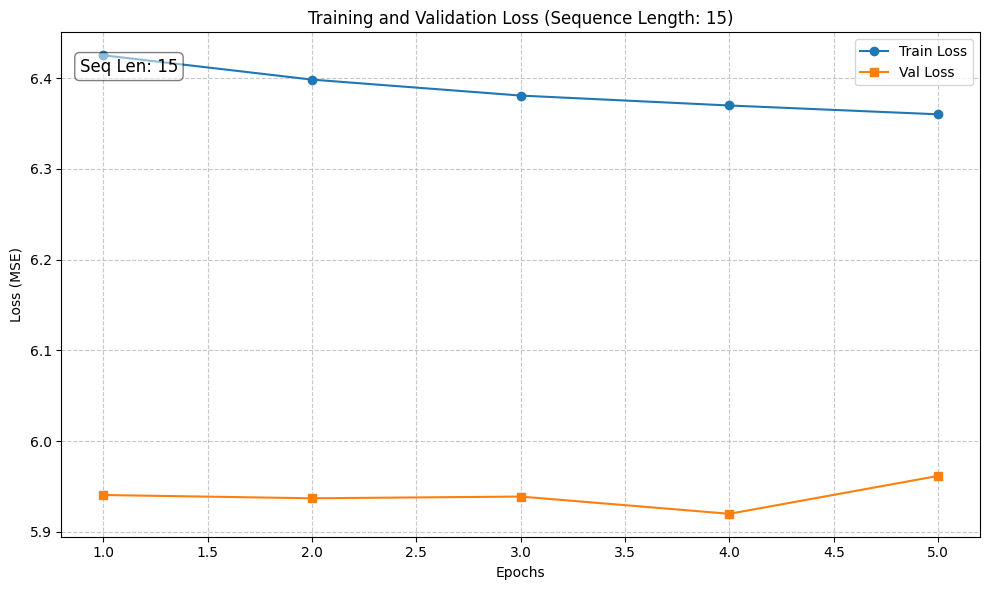


Training completed!


In [6]:
import matplotlib.pyplot as plt
import os

# 在训练开始前初始化记录器
history = {
    'train_loss': [],
    'val_loss': []
}

def plot_training_history(history, seq_len, save_path=f"training_loss_{seq_len}.png"):
    """绘制并保存训练曲线"""
    plt.figure(figsize=(10, 6))
    epochs_range = range(1, len(history['train_loss']) + 1)
    
    plt.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o')
    plt.plot(epochs_range, history['val_loss'], label='Val Loss', marker='s')
    
    # 添加标题和标签，包含 Sequence Length 标识
    plt.title(f'Training and Validation Loss (Sequence Length: {seq_len})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss (MSE)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # 在图中添加文本标注
    plt.text(0.02, 0.95, f'Seq Len: {seq_len}', transform=plt.gca().transAxes, 
             fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
    
    plt.tight_layout()
    plt.savefig(save_path)
    print(f"\nLoss plot saved to: {save_path}")
    plt.show()

# ===========================================================
# 开始全量训练 (修改部分)
# ===========================================================
print("\n" + "="*60)
print(f"Starting Full Training (Seq Len: {seq_len})...")
print("="*60)
best_val_loss = float('inf')
epochs =5
for epoch in range(epochs):
    # --- 训练阶段 ---
    model.train()
    train_loss = 0
    train_samples = 0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{epochs}")
    
    for batch_idx, (X, y) in enumerate(pbar):
        X, y = X.to(device), y.to(device)
        
        # (保持原有的前向传播、梯度裁剪、反向传播逻辑不变...)
        with torch.cuda.amp.autocast():
            pred = model(X)
            loss = criterion(pred, y)
        
        if torch.isnan(loss): continue
            
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        
        train_loss += loss.item() * X.size(0)
        train_samples += X.size(0)
        
        if batch_idx % 50 == 0:
            pbar.set_postfix({'avg_loss': f'{train_loss/train_samples:.6f}'})

    # --- 验证阶段 ---
    model.eval()
    val_loss = 0
    val_samples = 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            with torch.cuda.amp.autocast():
                pred = model(X)
                loss = criterion(pred, y)
            val_loss += loss.item() * X.size(0)
            val_samples += X.size(0)

    # --- 记录指标 ---
    epoch_train_avg = train_loss / train_samples
    epoch_val_avg = val_loss / val_samples
    history['train_loss'].append(epoch_train_avg)
    history['val_loss'].append(epoch_val_avg)
    
    print(f"\nEpoch {epoch+1:02d}: Train Loss: {epoch_train_avg:.6f} | Val Loss: {epoch_val_avg:.6f}")

    if epoch_val_avg < best_val_loss:
        best_val_loss = epoch_val_avg
        torch.save(model.state_dict(), "best_stable_model.pth")
        print(f"  ✓ Saved best model")

# 训练结束后调用绘图函数
plot_training_history(history, seq_len=seq_len)
print("\nTraining completed!")


Loss plot saved to: training_loss_15.png


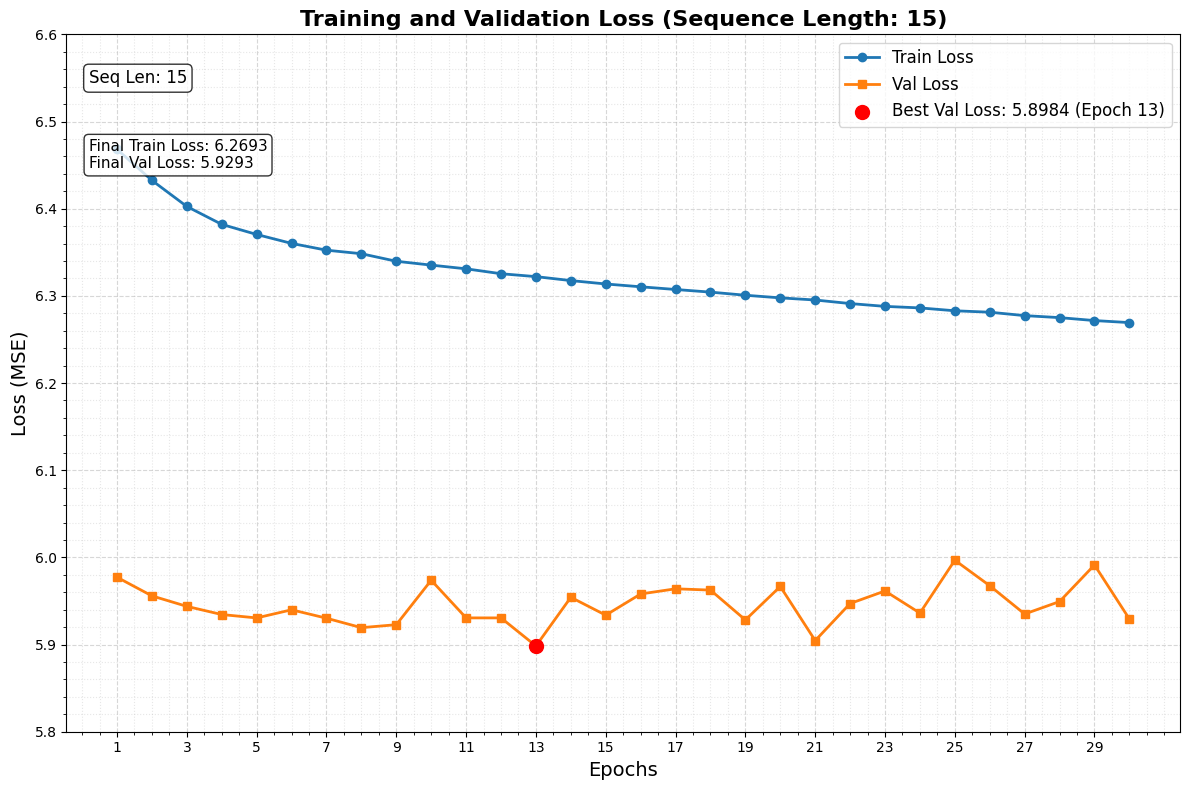


TRAINING SUMMARY:
Total Epochs: 30
Best Validation Loss: 5.898372 (Epoch 13)
Final Training Loss: 6.269319
Final Validation Loss: 5.929338
Training Loss Reduction: 0.198698 (3.07%)
Validation Loss Reduction: 0.047876 (0.80%)


In [2]:
import matplotlib.pyplot as plt
import numpy as np

# 从您的训练输出中提取的数据
train_losses = [
    6.468017, 6.432454, 6.402540, 6.381995, 6.370425,
    6.360169, 6.352394, 6.348340, 6.339680, 6.335266,
    6.331015, 6.325387, 6.322061, 6.317520, 6.313623,
    6.310401, 6.307294, 6.304284, 6.300704, 6.297688,
    6.295239, 6.291168, 6.287929, 6.286175, 6.282883,
    6.281234, 6.277329, 6.275022, 6.271655, 6.269319
]

val_losses = [
    5.977214, 5.955829, 5.943795, 5.934429, 5.930536,
    5.939873, 5.930224, 5.919365, 5.922776, 5.973776,
    5.930580, 5.930558, 5.898372, 5.954202, 5.933699,
    5.958023, 5.963945, 5.962465, 5.928235, 5.966617,
    5.904535, 5.947068, 5.961472, 5.936098, 5.996761,
    5.967485, 5.935045, 5.949324, 5.991303, 5.929338
]
seq_len =15 
# 使用您提供的函数格式
def plot_training_history(train_losses, val_losses, seq_len, save_path=f"training_loss_{seq_len}.png"):
    """绘制并保存训练曲线"""
    plt.figure(figsize=(12, 8))
    epochs_range = range(1, len(train_losses) + 1)
    
    plt.plot(epochs_range, train_losses, label='Train Loss', marker='o', linewidth=2, markersize=6)
    plt.plot(epochs_range, val_losses, label='Val Loss', marker='s', linewidth=2, markersize=6)
    
    # 添加标题和标签，包含 Sequence Length 标识
    plt.title(f'Training and Validation Loss (Sequence Length: {seq_len})', fontsize=16, fontweight='bold')
    plt.xlabel('Epochs', fontsize=14)
    plt.ylabel('Loss (MSE)', fontsize=14)
    
    # 设置坐标轴范围以更好地显示数据
    plt.ylim(5.8, 6.6)
    
    # 在图中添加标记最佳验证损失的点
    best_val_epoch = np.argmin(val_losses) + 1
    best_val_loss = min(val_losses)
    plt.scatter(best_val_epoch, best_val_loss, color='red', s=100, zorder=5, 
                label=f'Best Val Loss: {best_val_loss:.4f} (Epoch {best_val_epoch})')
    
    # 在图中添加文本标注
    plt.text(0.02, 0.95, f'Seq Len: {seq_len}', transform=plt.gca().transAxes, 
             fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # 添加总结信息
    final_train_loss = train_losses[-1]
    final_val_loss = val_losses[-1]
    summary_text = f'Final Train Loss: {final_train_loss:.4f}\nFinal Val Loss: {final_val_loss:.4f}'
    plt.text(0.02, 0.85, summary_text, transform=plt.gca().transAxes,
             fontsize=11, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xticks(range(1, len(train_losses) + 1, 2))
    
    # 添加次网格线
    plt.minorticks_on()
    plt.grid(True, which='minor', linestyle=':', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\nLoss plot saved to: {save_path}")
    plt.show()
    
    # 打印训练总结
    print("\n" + "="*60)
    print("TRAINING SUMMARY:")
    print("="*60)
    print(f"Total Epochs: {len(train_losses)}")
    print(f"Best Validation Loss: {best_val_loss:.6f} (Epoch {best_val_epoch})")
    print(f"Final Training Loss: {final_train_loss:.6f}")
    print(f"Final Validation Loss: {final_val_loss:.6f}")
    print(f"Training Loss Reduction: {(train_losses[0] - final_train_loss):.6f} ({((train_losses[0] - final_train_loss)/train_losses[0]*100):.2f}%)")
    print(f"Validation Loss Reduction: {(val_losses[0] - final_val_loss):.6f} ({((val_losses[0] - final_val_loss)/val_losses[0]*100):.2f}%)")
    print("="*60)

# 调用函数绘制曲线（假设seq_len=128，您可以根据实际情况修改）
seq_len =15 # 请根据您的实际序列长度修改
plot_training_history(train_losses, val_losses, seq_len)


Starting Full Training (Seq Len: 10)...


Epoch 01/5: 2131it [02:06, 16.82it/s, avg_loss=6.458874]



Epoch 01: Train Loss: 6.449169 | Val Loss: 5.965381
  ✓ Saved best model


Epoch 02/5: 2131it [01:55, 18.44it/s, avg_loss=6.420974]



Epoch 02: Train Loss: 6.412086 | Val Loss: 5.948395
  ✓ Saved best model


...


Epoch 03: Train Loss: 6.388761 | Val Loss: 5.930672
  ✓ Saved best model


Epoch 04/5: 2131it [01:59, 17.88it/s, avg_loss=6.401321]



Epoch 04: Train Loss: 6.372464 | Val Loss: 5.932718


Epoch 05/5: 2131it [01:58, 18.02it/s, avg_loss=6.323151]



Epoch 05: Train Loss: 6.363466 | Val Loss: 5.958065

Loss plot saved to: training_loss.png


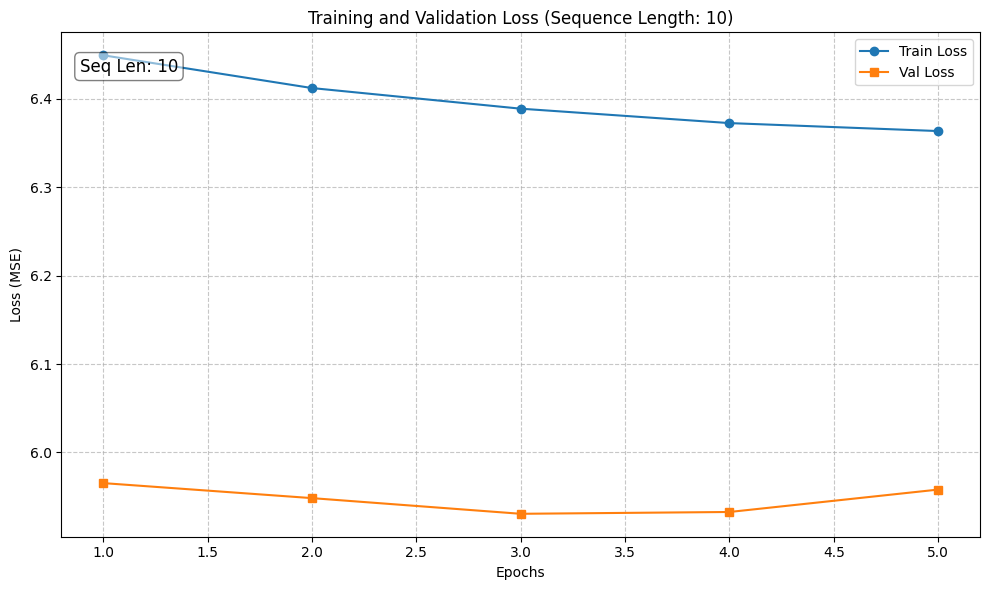


Training completed!


In [6]:
import matplotlib.pyplot as plt
import os

# 在训练开始前初始化记录器
history = {
    'train_loss': [],
    'val_loss': []
}

def plot_training_history(history, seq_len, save_path="training_loss.png"):
    """绘制并保存训练曲线"""
    plt.figure(figsize=(10, 6))
    epochs_range = range(1, len(history['train_loss']) + 1)
    
    plt.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o')
    plt.plot(epochs_range, history['val_loss'], label='Val Loss', marker='s')
    
    # 添加标题和标签，包含 Sequence Length 标识
    plt.title(f'Training and Validation Loss (Sequence Length: {seq_len})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss (MSE)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # 在图中添加文本标注
    plt.text(0.02, 0.95, f'Seq Len: {seq_len}', transform=plt.gca().transAxes, 
             fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
    
    plt.tight_layout()
    plt.savefig(save_path)
    print(f"\nLoss plot saved to: {save_path}")
    plt.show()

# ===========================================================
# 开始全量训练 (修改部分)
# ===========================================================
print("\n" + "="*60)
print(f"Starting Full Training (Seq Len: {seq_len})...")
print("="*60)
best_val_loss = float('inf')
epochs =5
for epoch in range(epochs):
    # --- 训练阶段 ---
    model.train()
    train_loss = 0
    train_samples = 0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{epochs}")
    
    for batch_idx, (X, y) in enumerate(pbar):
        X, y = X.to(device), y.to(device)
        
        # (保持原有的前向传播、梯度裁剪、反向传播逻辑不变...)
        with torch.cuda.amp.autocast():
            pred = model(X)
            loss = criterion(pred, y)
        
        if torch.isnan(loss): continue
            
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        
        train_loss += loss.item() * X.size(0)
        train_samples += X.size(0)
        
        if batch_idx % 50 == 0:
            pbar.set_postfix({'avg_loss': f'{train_loss/train_samples:.6f}'})

    # --- 验证阶段 ---
    model.eval()
    val_loss = 0
    val_samples = 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            with torch.cuda.amp.autocast():
                pred = model(X)
                loss = criterion(pred, y)
            val_loss += loss.item() * X.size(0)
            val_samples += X.size(0)

    # --- 记录指标 ---
    epoch_train_avg = train_loss / train_samples
    epoch_val_avg = val_loss / val_samples
    history['train_loss'].append(epoch_train_avg)
    history['val_loss'].append(epoch_val_avg)
    
    print(f"\nEpoch {epoch+1:02d}: Train Loss: {epoch_train_avg:.6f} | Val Loss: {epoch_val_avg:.6f}")

    if epoch_val_avg < best_val_loss:
        best_val_loss = epoch_val_avg
        torch.save(model.state_dict(), "best_stable_model.pth")
        print(f"  ✓ Saved best model")

# 训练结束后调用绘图函数
plot_training_history(history, seq_len=seq_len)
print("\nTraining completed!")

Using: cuda
Loading data and model...
Number of factor columns: 100
Error loading model: Error(s) in loading state_dict for StableTransformer:
	Unexpected key(s) in state_dict: "attention_pool.0.weight", "attention_pool.0.bias". 

Making predictions on validation set...


Predicting: 425it [00:20, 20.79it/s]


Predictions shape: (870197,)
Predictions range: [-12.1921, 10.6005]

Evaluation Metrics
MAE (Mean Absolute Error):  5.904349
MSE (Mean Squared Error):   77.951599
RMSE (Root MSE):            8.829021
R² Score:                   0.025163
sMAPE:                      165.04%
Correlation:                0.159190

Error Quantiles:
  Median Absolute Error:    4.115231
  75th Percentile Error:    7.771268
  90th Percentile Error:    12.855654
  95th Percentile Error:    17.122754

Error Statistics:
  Error Mean:               -0.037032
  Error Std:                8.828942
  Error Skewness:           0.251461
  Error Kurtosis:           27.435968

Metrics saved to: validation_results/validation_metrics.csv

Creating visualizations...


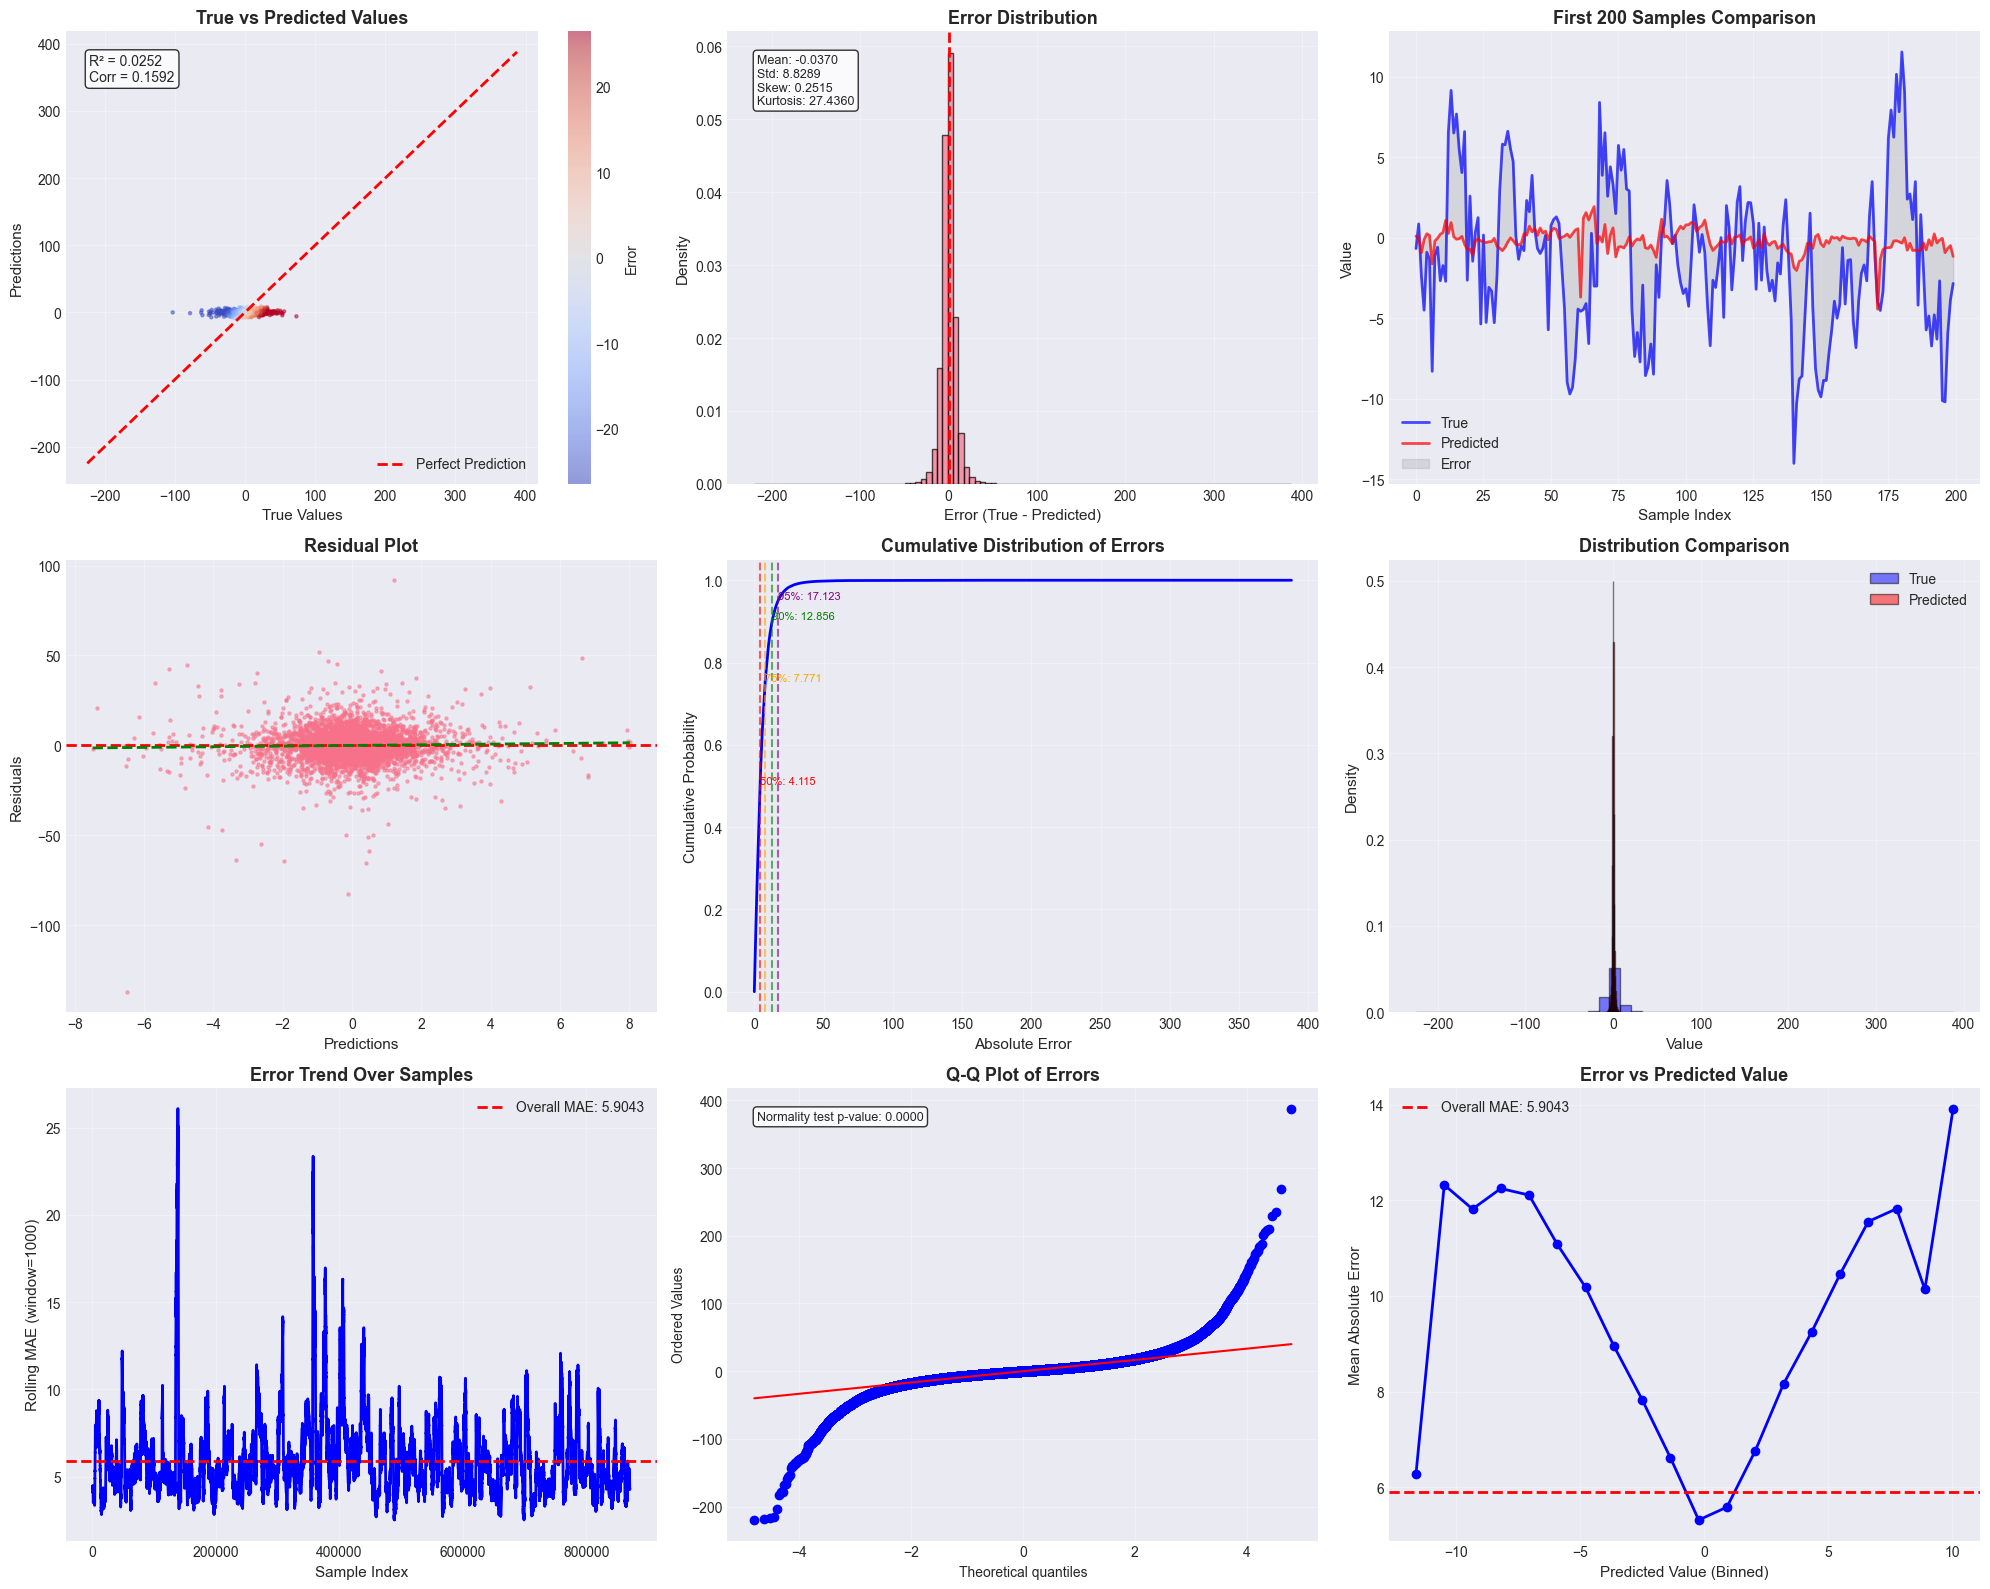

Visualization saved to: validation_results/validation_visualization.png

Saving detailed results...
Detailed predictions saved to: validation_results/detailed_predictions.csv
Group statistics saved to: validation_results/prediction_group_stats.csv

Group Statistics (first 5 groups):
                 true_value_mean  true_value_std  true_value_count  \
prediction_rank                                                      
0                      -2.749921       11.988004             87020   
1                      -1.064422        9.264927             87020   
2                      -0.651709        8.151204             87019   
3                      -0.288684        7.750616             87020   
4                      -0.115215        7.523453             87020   

                 predicted_value_mean  absolute_error_mean  \
prediction_rank                                              
0                           -2.456351             7.890668   
1                           -0.983974  

In [7]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
from pathlib import Path
import gc
from scipy import stats
warnings.filterwarnings("ignore")

# ===========================================================
# 1. 配置和加载
# ===========================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)
# 路径配置
val_path = r"D:\AFT\preprocess_val.parquet"
model_path = "best_stable_model_15.pth"
#model_path= 'best_ae_transformer.pth'
output_path = "validation_results"

# 创建输出目录
Path(output_path).mkdir(exist_ok=True)
# 训练时的参数（需要和训练时一致）
seq_len =15
batch_size = 1024
# ===========================================================
# 2. 加载数据和模型架构
# ===========================================================
print("Loading data and model...")
# 加载数据并获取因子列
train_path = r"D:\AFT\preprocess_train.parquet"
train_lazy = pl.scan_parquet(train_path)
factor_cols = [col for col in train_lazy.collect_schema().names() 
               if col not in ["date_id", "stock_id",'seconds_in_bucket', "target"]]

print(f"Number of factor columns: {len(factor_cols)}")

# 定义与训练时相同的模型架构
class StableTransformer(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_heads=4, num_layers=2, dropout=0.1):
        super().__init__()
        self.input_norm = nn.BatchNorm1d(input_dim)
        self.input_proj = nn.Linear(input_dim, hidden_dim)
        # 位置编
        position = torch.arange(seq_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, hidden_dim, 2).float() * -(np.log(10000.0) / hidden_dim))
        pe = torch.zeros(1, seq_len, hidden_dim)
        pe[0, :, 0::2] = torch.sin(position * div_term)
        pe[0, :, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe * 0.1)
        # Transformer层
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=hidden_dim * 2,
            dropout=dropout,
            batch_first=True,
            activation='relu',
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        # 输出层
        self.output_norm = nn.LayerNorm(hidden_dim)
        self.output = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        # BatchNorm
        batch_size, seq_len, features = x.shape
        x_flat = x.reshape(-1, features)
        x_flat = self.input_norm(x_flat)
        x = x_flat.reshape(batch_size, seq_len, features)
        # 输入投影
        x = self.input_proj(x)
        x = x + self.pe
        # Transformer
        x = self.transformer(x)
        # 输出
        x = self.output_norm(x)
        x = x.mean(dim=1)
        x = self.output(x)
        return x.squeeze(-1)

# 创建模型
model = StableTransformer(
    input_dim=len(factor_cols),
    hidden_dim=64,
    num_heads=4,
    num_layers=2
).to(device)

# 加载训练好的权重
try:
    checkpoint = torch.load(model_path, map_location=device)
    if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
        model.load_state_dict(checkpoint['model_state_dict'])
        print(f"Loaded model from checkpoint")
    else:
        model.load_state_dict(checkpoint)
        print(f"Loaded model weights")
    print("Model loaded successfully!")
    
except Exception as e:
    print(f"Error loading model: {e}")
    exit(1)

# # ===========================================================
# # 3. 创建验证数据集
# # ===========================================================

# print("\nPreparing validation data...")

# class ValidationDataset:
#     def __init__(self, parquet_path, seq_len, factor_cols):
#         self.path = parquet_path
#         self.seq_len = seq_len
#         self.factor_cols = factor_cols
#         # 加载数据
#         print(f"Loading data from {parquet_path}...")
#         self.df = pl.scan_parquet(parquet_path).collect()
#         self.total_samples = len(self.df) - seq_len
#         # 提取特征和目标
#         self.X_all = self.df.select(factor_cols).to_numpy().astype(np.float32)
#         self.y_all = self.df.select("target").to_numpy().flatten().astype(np.float32)
#         # 预处理
#         self._preprocess()
        
#     def _preprocess(self):
#         """数据预处理"""
#         print("Preprocessing data...")
#         # 1. 处理NaN和Inf
#         self.X_all = np.nan_to_num(self.X_all, nan=0.0, posinf=1e6, neginf=-1e6)
#         self.y_all = np.nan_to_num(self.y_all, nan=0.0, posinf=1e6, neginf=-1e6)
#         # 2. 简单归一化
#         self.X_mean = np.mean(self.X_all, axis=0)
#         self.X_std = np.std(self.X_all, axis=0)
#         self.X_std[self.X_std == 0] = 1.0
#         self.X_all = (self.X_all - self.X_mean) / self.X_std
#         print(f"Data shape: X={self.X_all.shape}, y={self.y_all.shape}")
#         print(f"Target range: [{self.y_all.min():.4f}, {self.y_all.max():.4f}]")
#         print(f"Target mean: {self.y_all.mean():.4f}, std: {self.y_all.std():.4f}")
#     def __len__(self):
#         return self.total_samples
#     def __getitem__(self, idx):
#         X_seq = self.X_all[idx:idx+self.seq_len]
#         y_val = self.y_all[idx+self.seq_len-1]
#         return (
#             torch.from_numpy(X_seq.copy()).float(),
#             torch.tensor(y_val).float()
#         )

# # 创建验证数据集
# val_dataset = ValidationDataset(val_path, seq_len, factor_cols)
# val_loader = torch.utils.data.DataLoader(
#     val_dataset,
#     batch_size=batch_size,
#     shuffle=False,
#     num_workers=0,
#     pin_memory=True
# )
# print(f"Validation samples: {len(val_dataset):,}")

# ===========================================================
# 4. 在验证集上进行预测
# ===========================================================

print("\n" + "="*60)
print("Making predictions on validation set...")
print("="*60)

model.eval()
all_predictions = []
all_targets = []
all_errors = []

with torch.no_grad():
    for X, y in tqdm(val_loader, desc="Predicting"):
        X, y = X.to(device), y.to(device)
        
        # 预测
        predictions = model(X)
        
        # 收集结果
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(y.cpu().numpy())
        all_errors.append((y - predictions).cpu().numpy())

# 合并结果
all_predictions = np.concatenate(all_predictions)
all_targets = np.concatenate(all_targets)
all_errors = np.concatenate(all_errors)

print(f"Predictions shape: {all_predictions.shape}")
print(f"Predictions range: [{all_predictions.min():.4f}, {all_predictions.max():.4f}]")

# ===========================================================
# 5. 计算评估指标
# ===========================================================

print("\n" + "="*60)
print("Evaluation Metrics")
print("="*60)

# 基础指标
mae = np.mean(np.abs(all_errors))
mse = np.mean(all_errors ** 2)
rmse = np.sqrt(mse)

# R² score
ss_res = np.sum(all_errors ** 2)
ss_tot = np.sum((all_targets - np.mean(all_targets)) ** 2)
r2 = 1 - (ss_res / ss_tot)

# 对称平均绝对百分比误差
def smape(y_true, y_pred):
    denominator = (np.abs(y_true) + np.abs(y_pred))
    # 避免除零
    denominator = np.where(denominator == 0, 1.0, denominator)
    return 2.0 * np.mean(np.abs(y_pred - y_true) / denominator) * 100

smape_val = smape(all_targets, all_predictions)

# 分位数误差
def quantile_error(y_true, y_pred, q=0.5):
    errors = y_true - y_pred
    return np.quantile(np.abs(errors), q)

q50 = quantile_error(all_targets, all_predictions, 0.5)
q75 = quantile_error(all_targets, all_predictions, 0.75)
q90 = quantile_error(all_targets, all_predictions, 0.90)
q95 = quantile_error(all_targets, all_predictions, 0.95)

# 相关系数
correlation = np.corrcoef(all_targets, all_predictions)[0, 1]

print(f"MAE (Mean Absolute Error):  {mae:.6f}")
print(f"MSE (Mean Squared Error):   {mse:.6f}")
print(f"RMSE (Root MSE):            {rmse:.6f}")
print(f"R² Score:                   {r2:.6f}")
print(f"sMAPE:                      {smape_val:.2f}%")
print(f"Correlation:                {correlation:.6f}")
print(f"\nError Quantiles:")
print(f"  Median Absolute Error:    {q50:.6f}")
print(f"  75th Percentile Error:    {q75:.6f}")
print(f"  90th Percentile Error:    {q90:.6f}")
print(f"  95th Percentile Error:    {q95:.6f}")
print(f"\nError Statistics:")
print(f"  Error Mean:               {all_errors.mean():.6f}")
print(f"  Error Std:                {all_errors.std():.6f}")
print(f"  Error Skewness:           {stats.skew(all_errors):.6f}")
print(f"  Error Kurtosis:           {stats.kurtosis(all_errors):.6f}")

# 保存指标到文件
metrics_df = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2', 'sMAPE', 'Correlation', 
               'Median_Error', 'P75_Error', 'P90_Error', 'P95_Error',
               'Error_Mean', 'Error_Std', 'Error_Skew', 'Error_Kurtosis'],
    'Value': [mae, mse, rmse, r2, smape_val, correlation,
              q50, q75, q90, q95,
              all_errors.mean(), all_errors.std(), 
              stats.skew(all_errors), stats.kurtosis(all_errors)]
})
metrics_df.to_csv(f"{output_path}/validation_metrics.csv", index=False)
print(f"\nMetrics saved to: {output_path}/validation_metrics.csv")

# ===========================================================
# 6. 可视化结果
# ===========================================================

print("\n" + "="*60)
print("Creating visualizations...")
print("="*60)

# 设置样式
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# 创建一个大画布
fig = plt.figure(figsize=(20, 16))

# 1. 真实值 vs 预测值散点图
ax1 = plt.subplot(3, 3, 1)
# 为了性能，只使用部分数据
sample_indices = np.random.choice(len(all_targets), size=min(10000, len(all_targets)), replace=False)
scatter = ax1.scatter(all_targets[sample_indices], all_predictions[sample_indices], 
                      alpha=0.5, s=5, c=all_errors[sample_indices], 
                      cmap='coolwarm', vmin=-3*all_errors.std(), vmax=3*all_errors.std())
ax1.plot([all_targets.min(), all_targets.max()], 
         [all_targets.min(), all_targets.max()], 'r--', lw=2, label='Perfect Prediction')
ax1.set_xlabel('True Values', fontsize=11)
ax1.set_ylabel('Predictions', fontsize=11)
ax1.set_title('True vs Predicted Values', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax1, label='Error')

# 添加对角线上的指标
ax1.text(0.05, 0.95, f'R² = {r2:.4f}\nCorr = {correlation:.4f}', 
         transform=ax1.transAxes, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# 2. 误差分布直方图
ax2 = plt.subplot(3, 3, 2)
n_bins = min(100, int(len(all_errors) / 100))
ax2.hist(all_errors, bins=n_bins, edgecolor='black', alpha=0.7, density=True)
ax2.axvline(x=0, color='r', linestyle='--', linewidth=2)
ax2.set_xlabel('Error (True - Predicted)', fontsize=11)
ax2.set_ylabel('Density', fontsize=11)
ax2.set_title('Error Distribution', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

# 添加统计信息到误差图
error_stats_text = (f'Mean: {all_errors.mean():.4f}\n'
                    f'Std: {all_errors.std():.4f}\n'
                    f'Skew: {stats.skew(all_errors):.4f}\n'
                    f'Kurtosis: {stats.kurtosis(all_errors):.4f}')
ax2.text(0.05, 0.95, error_stats_text, transform=ax2.transAxes, 
         verticalalignment='top', fontsize=9,
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# 3. 前200个样本对比
ax3 = plt.subplot(3, 3, 3)
sample_idx = np.arange(200)
ax3.plot(sample_idx, all_targets[:200], 'b-', label='True', linewidth=2, alpha=0.7)
ax3.plot(sample_idx, all_predictions[:200], 'r-', label='Predicted', linewidth=2, alpha=0.7)
ax3.fill_between(sample_idx, all_targets[:200], all_predictions[:200], 
                 alpha=0.2, color='gray', label='Error')
ax3.set_xlabel('Sample Index', fontsize=11)
ax3.set_ylabel('Value', fontsize=11)
ax3.set_title('First 200 Samples Comparison', fontsize=13, fontweight='bold')
ax3.legend(fontsize=10)
ax3.grid(True, alpha=0.3)

# 4. 残差图
ax4 = plt.subplot(3, 3, 4)
sample_indices_res = np.random.choice(len(all_predictions), size=min(5000, len(all_predictions)), replace=False)
ax4.scatter(all_predictions[sample_indices_res], all_errors[sample_indices_res], 
            alpha=0.5, s=5)
ax4.axhline(y=0, color='r', linestyle='--', linewidth=2)
ax4.set_xlabel('Predictions', fontsize=11)
ax4.set_ylabel('Residuals', fontsize=11)
ax4.set_title('Residual Plot', fontsize=13, fontweight='bold')
ax4.grid(True, alpha=0.3)

# 添加残差趋势线
z = np.polyfit(all_predictions[sample_indices_res], all_errors[sample_indices_res], 1)
p = np.poly1d(z)
sorted_preds = np.sort(all_predictions[sample_indices_res])
ax4.plot(sorted_preds, p(sorted_preds), "g--", linewidth=2, label='Trend')

# 5. 累积分布函数
ax5 = plt.subplot(3, 3, 5)
sorted_errors = np.sort(np.abs(all_errors))
cdf = np.arange(1, len(sorted_errors)+1) / len(sorted_errors)
ax5.plot(sorted_errors, cdf, 'b-', linewidth=2)
ax5.set_xlabel('Absolute Error', fontsize=11)
ax5.set_ylabel('Cumulative Probability', fontsize=11)
ax5.set_title('Cumulative Distribution of Errors', fontsize=13, fontweight='bold')
ax5.grid(True, alpha=0.3)

# 添加关键分位数线
for q, color in [(0.5, 'red'), (0.75, 'orange'), (0.9, 'green'), (0.95, 'purple')]:
    error_q = np.quantile(np.abs(all_errors), q)
    ax5.axvline(x=error_q, color=color, linestyle='--', alpha=0.6)
    ax5.text(error_q, q, f'{q*100:.0f}%: {error_q:.3f}', 
             horizontalalignment='left', verticalalignment='bottom',
             fontsize=8, color=color)

# 6. 预测值分布 vs 真实值分布
ax6 = plt.subplot(3, 3, 6)
n_bins = min(50, int(len(all_targets) / 1000))
ax6.hist(all_targets, bins=n_bins, alpha=0.5, label='True', density=True, 
         edgecolor='black', color='blue')
ax6.hist(all_predictions, bins=n_bins, alpha=0.5, label='Predicted', density=True, 
         edgecolor='black', color='red')
ax6.set_xlabel('Value', fontsize=11)
ax6.set_ylabel('Density', fontsize=11)
ax6.set_title('Distribution Comparison', fontsize=13, fontweight='bold')
ax6.legend(fontsize=10)
ax6.grid(True, alpha=0.3)

# 7. 滚动MAE
ax7 = plt.subplot(3, 3, 7)
window_size = min(1000, len(all_errors) // 10)
if window_size > 10:
    rolling_mae = pd.Series(np.abs(all_errors)).rolling(window=window_size).mean()
    ax7.plot(rolling_mae.index, rolling_mae.values, 'b-', linewidth=2)
    ax7.axhline(y=mae, color='r', linestyle='--', linewidth=2, label=f'Overall MAE: {mae:.4f}')
    ax7.set_xlabel('Sample Index', fontsize=11)
    ax7.set_ylabel(f'Rolling MAE (window={window_size})', fontsize=11)
    ax7.set_title('Error Trend Over Samples', fontsize=13, fontweight='bold')
    ax7.legend(fontsize=10)
    ax7.grid(True, alpha=0.3)
else:
    ax7.text(0.5, 0.5, 'Not enough data for rolling MAE', 
             horizontalalignment='center', verticalalignment='center',
             transform=ax7.transAxes, fontsize=12)
    ax7.set_title('Error Trend (Insufficient Data)', fontsize=13, fontweight='bold')

# 8. 分位数-分位数图
ax8 = plt.subplot(3, 3, 8)
stats.probplot(all_errors, dist="norm", plot=ax8)
ax8.set_title('Q-Q Plot of Errors', fontsize=13, fontweight='bold')
ax8.grid(True, alpha=0.3)

# 添加正态性检验结果
_, p_value = stats.normaltest(all_errors)
normality_text = f'Normality test p-value: {p_value:.4f}'
ax8.text(0.05, 0.95, normality_text, transform=ax8.transAxes, 
         verticalalignment='top', fontsize=9,
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# 9. 预测误差 vs 预测值
ax9 = plt.subplot(3, 3, 9)
abs_errors = np.abs(all_errors)
# 分箱分析
n_bins = 20
bin_edges = np.linspace(all_predictions.min(), all_predictions.max(), n_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_errors = []

for i in range(n_bins):
    mask = (all_predictions >= bin_edges[i]) & (all_predictions < bin_edges[i+1])
    if np.sum(mask) > 0:
        bin_errors.append(np.mean(abs_errors[mask]))
    else:
        bin_errors.append(np.nan)

ax9.plot(bin_centers, bin_errors, 'bo-', linewidth=2, markersize=6)
ax9.axhline(y=mae, color='r', linestyle='--', linewidth=2, label=f'Overall MAE: {mae:.4f}')
ax9.set_xlabel('Predicted Value (Binned)', fontsize=11)
ax9.set_ylabel('Mean Absolute Error', fontsize=11)
ax9.set_title('Error vs Predicted Value', fontsize=13, fontweight='bold')
ax9.legend(fontsize=10)
ax9.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{output_path}/validation_visualization.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Visualization saved to: {output_path}/validation_visualization.png")
# ===========================================================
# 7. 保存详细预测结果
# ===========================================================
print("\nSaving detailed results...")
# 创建详细的结果DataFrame
results_df = pd.DataFrame({
    'true_value': all_targets,
    'predicted_value': all_predictions,
    'absolute_error': np.abs(all_errors),
    'signed_error': all_errors,
    'prediction_rank': pd.qcut(all_predictions, q=10, labels=False, duplicates='drop'),
    'true_rank': pd.qcut(all_targets, q=10, labels=False, duplicates='drop'),
})
# 添加额外的统计信息
mask = np.abs(all_targets) > 1e-8  # 避免除零
results_df['error_percentage'] = np.where(
    mask, 
    np.abs(all_errors) / np.abs(all_targets) * 100,
    np.nan
)
# 保存到CSV
results_df.to_csv(f'{output_path}/detailed_predictions.csv', index=False)
print(f"Detailed predictions saved to: {output_path}/detailed_predictions.csv")
# 保存预测分组的统计信息
group_stats = results_df.groupby('prediction_rank').agg({
    'true_value': ['mean', 'std', 'count'],
    'predicted_value': 'mean',
    'absolute_error': 'mean',
    'error_percentage': 'mean'
}).round(6)
group_stats.columns = ['_'.join(col).strip() for col in group_stats.columns.values]
group_stats.to_csv(f'{output_path}/prediction_group_stats.csv')
print(f"Group statistics saved to: {output_path}/prediction_group_stats.csv")
# 打印前几个分组的统计
print("\nGroup Statistics (first 5 groups):")
print(group_stats.head())
# 8. 创建总结报告
print("\n" + "="*60)
print("SUMMARY REPORT")
print("="*60)
# 模型信息
model_info = {
    'Model Type': 'Transformer',
    'Sequence Length': seq_len,
    'Batch Size': batch_size,
    'Input Dimension': len(factor_cols),
    'Hidden Dimension': 64,
    'Number of Heads': 4,
    'Number of Layers': 2,
    'Total Parameters': f"{sum(p.numel() for p in model.parameters()):,}"
}
print("\nModel Configuration:")
for key, value in model_info.items():
    print(f"  {key:25s}: {value}")
print("\n" + "="*60)
print("Validation Complete!")
print(f"All results saved to: {output_path}/")
print("="*60)